<a href="https://colab.research.google.com/github/kmathiyarasu/AIML_2ndInnings/blob/aiml_explore_basics1/intro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from sklearn.datasets import load_iris
iris = load_iris()

In [ ]:
import pandas as pd
X = pd.DataFrame(iris.data, columns=iris.feature_names)
X.head()

y =pd.Series(iris.target)

In [ ]:
df= X.copy()
df['target'] = y
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


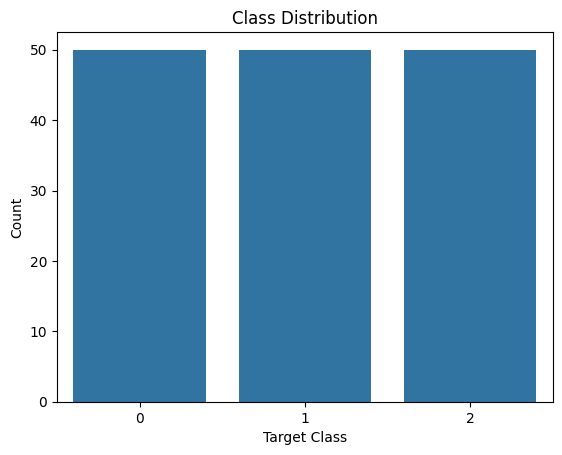

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x=df['target'])

plt.title("Class Distribution")
plt.xlabel("Target Class")
plt.ylabel("Count")
plt.show()

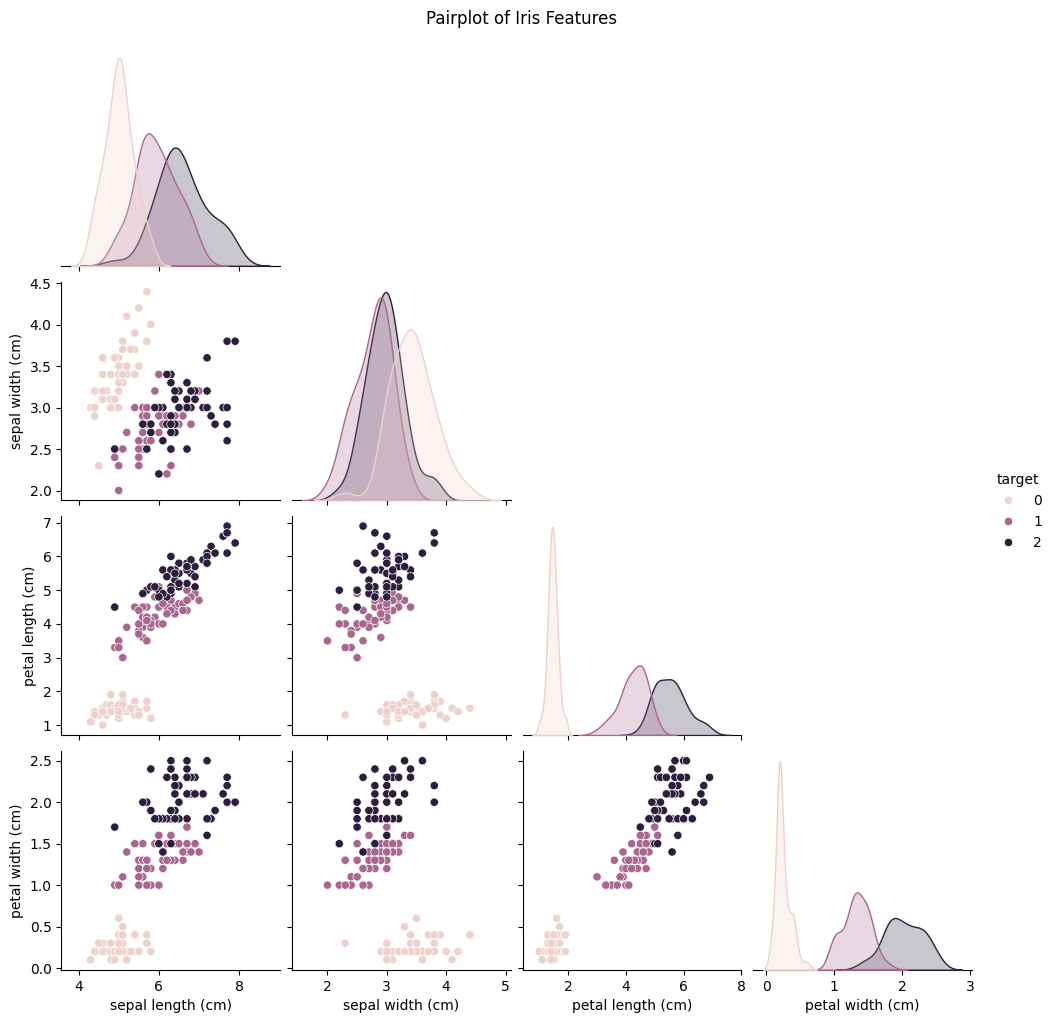

In [ ]:
sns.pairplot(df, hue='target',  corner=True)
plt.suptitle("Pairplot of Iris Features", y=1.02)
plt.show()

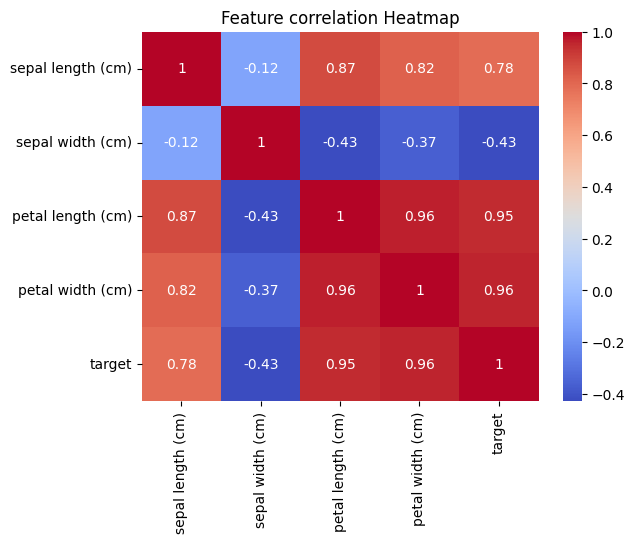

In [ ]:
sns.heatmap(df.corr(),annot=True,cmap="coolwarm")
plt.title("Feature correlation Heatmap")
plt.show()

Data Preprocessing:
------------------

In [ ]:
 from sklearn.model_selection import train_test_split
 X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
 from sklearn.preprocessing import StandardScaler

 scaler = StandardScaler()
 X_train = scaler.fit_transform(X_train)
 X_test = scaler.transform(X_test)

Visualize Feature Distribution:

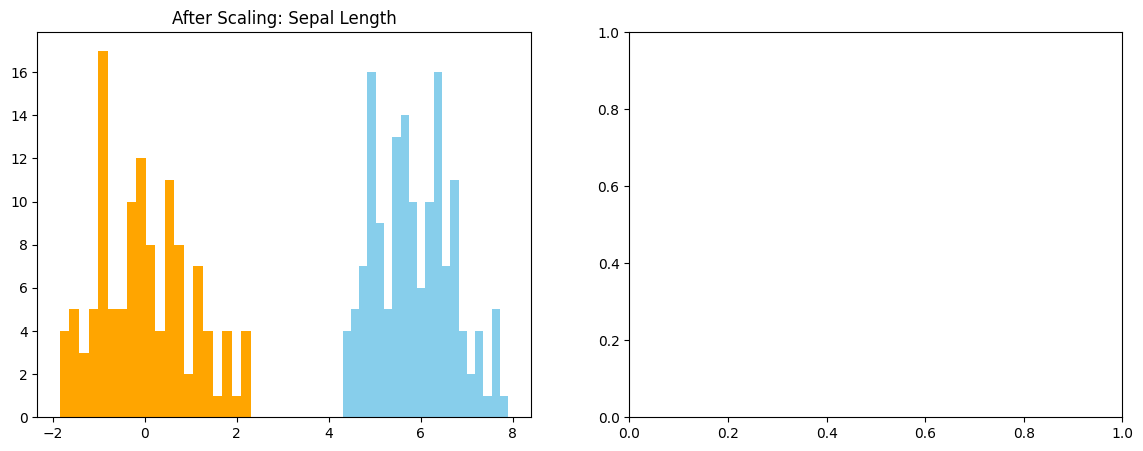

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].hist(X.iloc[:, 0], bins=20, color="skyblue")
ax[0].set_title("Before Scaling: Sepal Length")

ax[0].hist(X_train[:, 0], bins=20, color="orange")
ax[0].set_title("After Scaling: Sepal Length")
plt.show()

ML models in sklearn: KNN and Decision Trees

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)

In [ ]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(X_train, y_train)
y_pred_tree = tree.predict(X_test)

Confusion Matrix Heatmap (for both KNN and Decision Tree models)

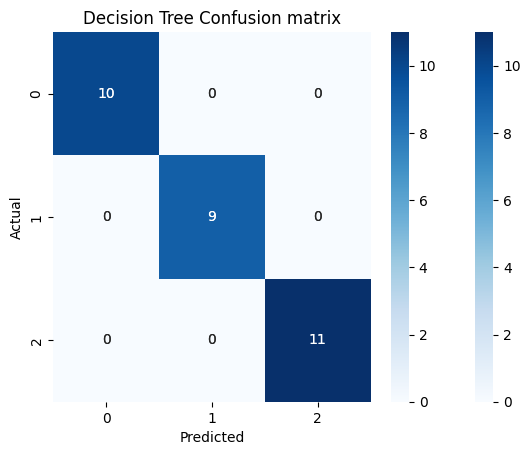

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

def plot_confusion(y_true, y_pred, title):
  cm = confusion_matrix(y_true, y_pred)
  sns.heatmap(cm, annot=True, fmt='d', cmap="Blues")
  plt.xlabel("Predicted")
  plt.ylabel("Actual")
  plt.title(title)


plot_confusion(y_test, y_pred_knn, "KNN Confusion matrix")




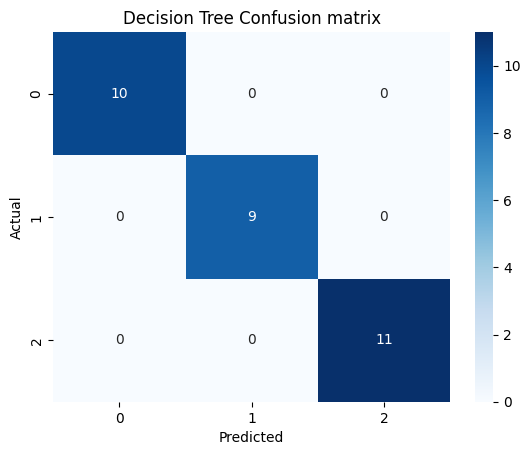

In [ ]:
plot_confusion(y_test, y_pred_tree, "Decision Tree Confusion matrix")

In [ ]:
print("KNN Report:\n", classification_report(y_test, y_pred_knn))
print("Tree Report:\n", classification_report(y_test, y_pred_tree))

KNN Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

Tree Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

